# CAPSTONE PROJECT 1
## Working with NumPy Matrices (Multidimensional Data)

### Introduction
This project analyses body measurements of adult male and female participants
using NumPy matrices and Python data visualization libraries.

The analysis includes statistical summaries, BMI calculations,
data standardization, correlation analysis, and visual comparisons.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Loading the Datasets

In [4]:
male = np.loadtxt("nhanes_adult_male_bmx_2020.csv",
                  delimiter=",", skiprows=19)

female = np.loadtxt("nhanes_adult_female_bmx_2020.csv",
                    delimiter=",", skiprows=19)

# 2. Understanding the Dataset

In [5]:
print("Male dataset shape:", male.shape)
print("Female dataset shape:", female.shape)

print("\nFirst 5 rows of male dataset:")
print(male[:5])

print("\nFirst 5 rows of female dataset:")
print(female[:5])

Male dataset shape: (4081, 7)
Female dataset shape: (4221, 7)

First 5 rows of male dataset:
[[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]
 [ 99.4 181.6  40.4  39.9  36.  120.2 107. ]]

First 5 rows of female dataset:
[[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]
 [ 55.4 154.6  34.6  34.   28.3  92.5  73.2]]


# 3. Weight Distribution Analysis

This section visualises the weight distributions of adult male and
female participants using histograms. Both histograms use identical
x-axis limits to enable a fair visual comparison.

In [6]:
female_weights = female[:, 0]
male_weights = male[:, 0]

print("Female weights:", female_weights[:10])
print("Male weights:", male_weights[:10])


Female weights: [97.1 91.1 73.  61.7 55.4 62.  66.2 75.9 77.2 91.6]
Male weights: [ 98.8  74.3 103.7  86.   99.4  90.2  45.5  64.   67.9  75.2]


In [7]:
min_weight = min(np.min(female_weights), np.min(male_weights))
max_weight = max(np.max(female_weights), np.max(male_weights))

print("Minimum weight:", min_weight)
print("Maximum weight:", max_weight)

Minimum weight: 32.6
Maximum weight: 204.6


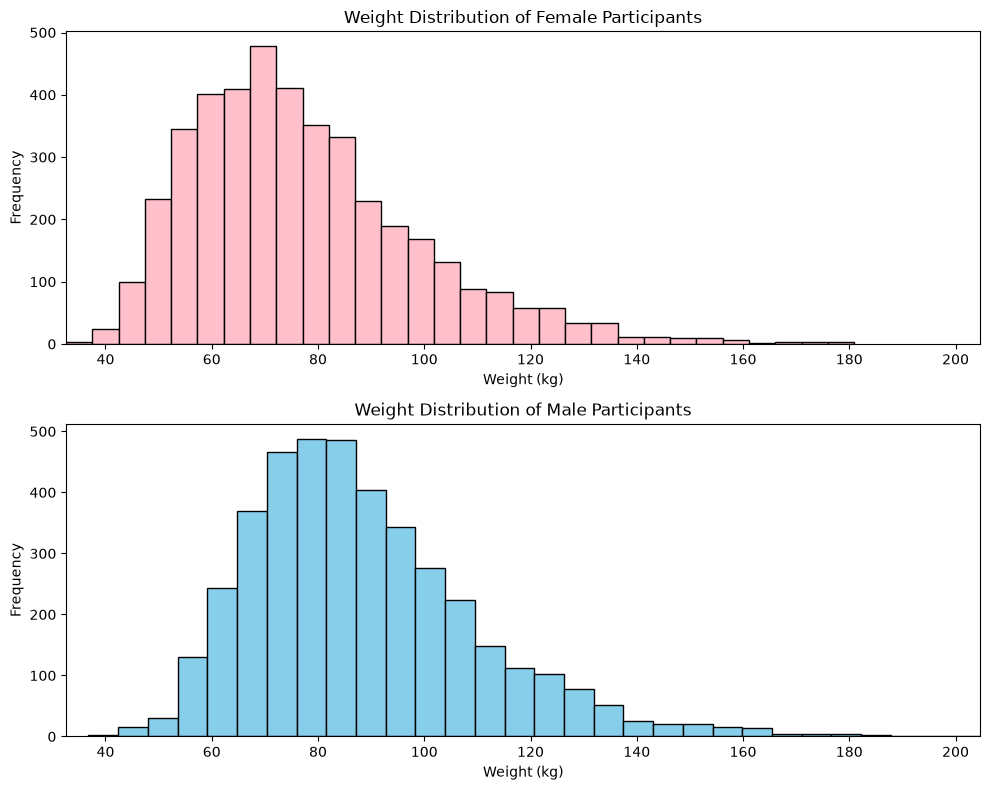

In [8]:
plt.figure(figsize=(10, 8))

# Female 
plt.subplot(2, 1, 1)

plt.hist(female_weights, bins=30,
         color='pink', edgecolor='black')

plt.title("Weight Distribution of Female Participants")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(min_weight, max_weight)

# Male 
plt.subplot(2, 1, 2)

plt.hist(male_weights, bins=30,
         color='skyblue', edgecolor='black')

plt.title("Weight Distribution of Male Participants")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(min_weight, max_weight)

plt.tight_layout()
plt.show()

### Interpretation of Weight Distributions

The histograms illustrate the weight distributions of adult male and female participants.

The female weight distribution is mainly concentrated between approximately 60 kg and 80 kg, with the highest frequency occurring around 65–75 kg. Similarly, the male weight distribution is concentrated mainly between approximately 70 kg and 100 kg, with its highest frequency around 80–90 kg.

Both distributions exhibit positive (right) skewness, as their tails extend towards higher weight values. The male distribution appears shifted towards higher weights compared to the female distribution.

Overall, the histograms indicate differences in the weight distributions of male and female participants.

# 4. Comparison of Male and Female Weight Distributions Using Boxplots

A box-and-whisker plot is used to compare the weight distributions of male and female participants. It provides information about the median, quartiles, spread, and potential outliers in each dataset.


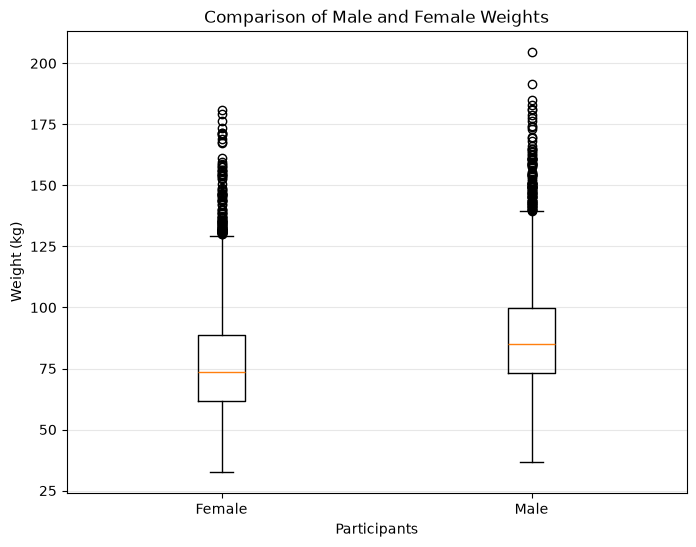

In [9]:
plt.figure(figsize=(8, 6))

plt.boxplot(
    [female_weights, male_weights],
    tick_labels=["Female", "Male"]
)

plt.title("Comparison of Male and Female Weights")
plt.ylabel("Weight (kg)")
plt.xlabel("Participants")

plt.grid(axis='y', alpha=0.3)
plt.show()

### Interpretation of Box-and-Whisker Plot

The box-and-whisker plot compares the weight distributions of male and female participants.

The median weight of male participants is higher than that of female participants, indicating that male participants generally have higher weights in this dataset.

The interquartile ranges of both groups are approximately similar, suggesting that the variation in the middle 50% of their weight distributions is comparable. The female distribution appears to have a slightly larger interquartile range.

Both distributions contain several upper outliers, representing participants with unusually high weights compared to the majority of observations.

Overall, the boxplot shows that male participants have a higher median weight, while the central spread of weights is similar for both groups.

# 5. Statistical Analysis of Male and Female Weight Distributions

This section calculates and compares the basic numerical aggregates of male and female body weights. The analysis includes measures of location, dispersion, and shape to understand the characteristics of both distributions.

In [10]:
# female weights

print("FEMALE WEIGHT STATISTICS")

print("Mean:", np.mean(female_weights))
print("Median:", np.median(female_weights))

print("Minimum:", np.min(female_weights))
print("Maximum:", np.max(female_weights))
print("Range:", np.ptp(female_weights))

print("Variance:", np.var(female_weights))
print("Standard Deviation:", np.std(female_weights))

print("Skewness:", stats.skew(female_weights, bias=False))
print("Kurtosis:", stats.kurtosis(female_weights, fisher=True, bias=False))


# male weights

print("\nMALE WEIGHT STATISTICS")

print("Mean:", np.mean(male_weights))
print("Median:", np.median(male_weights))

print("Minimum:", np.min(male_weights))
print("Maximum:", np.max(male_weights))
print("Range:", np.ptp(male_weights))

print("Variance:", np.var(male_weights))
print("Standard Deviation:", np.std(male_weights))

print("Skewness:", stats.skew(male_weights, bias=False))
print("Kurtosis:", stats.kurtosis(male_weights, fisher=True, bias=False))

FEMALE WEIGHT STATISTICS
Mean: 77.40379057095475
Median: 73.6
Minimum: 32.6
Maximum: 180.9
Range: 148.3
Variance: 464.07966343304065
Standard Deviation: 21.54250829019315
Skewness: 1.0337284601122165
Kurtosis: 1.404052098673703

MALE WEIGHT STATISTICS
Mean: 88.36454300416565
Median: 85.0
Minimum: 36.8
Maximum: 204.6
Range: 167.8
Variance: 458.770850128082
Standard Deviation: 21.418936717962495
Skewness: 0.984643023531097
Kurtosis: 1.4775680236244009


### Interpretation of Statistical Results

The numerical analysis reveals several differences and similarities between the male and female weight distributions.

**Measures of Location:**

The mean weight of male participants (88.36 kg) is higher than that of female participants (77.40 kg). Similarly, the male median (85 kg) is higher than the female median (73.60 kg). In both groups, the mean is greater than the median, indicating positive skewness.

**Measures of Dispersion:**

The male weight distribution has a larger range (167.80 kg) compared to the female distribution (148.30 kg). However, the female distribution has slightly higher variance (464.08 kg²) and standard deviation (21.54 kg) than the male distribution (458.77 kg² and 21.42 kg, respectively). The standard deviations are nearly identical, indicating similar overall variability in weights around their respective means.

**Measures of Shape:**

Both distributions have positive skewness values, indicating right-skewed distributions. The female distribution is slightly more positively skewed (1.034) than the male distribution (0.985).

Both distributions also have positive excess kurtosis values, indicating heavier tails compared to a normal distribution. The male distribution has slightly higher excess kurtosis (1.478) than the female distribution (1.404).

**Overall Conclusion:**

Male participants have higher average and median weights than female participants. Although the male distribution has a larger range, both groups have nearly identical standard deviations. Both distributions are positively skewed and exhibit heavier tails than a normal distribution.

# 6. BMI Calculation

In [11]:
female_weight = female[:, 0]
female_height = female[:, 1]

In [12]:
female_height_m = female_height / 100

In [13]:
bmi = female_weight / (female_height_m ** 2)

In [14]:
female = np.column_stack((female, bmi))

In [15]:
print("Updated female dataset shape:", female.shape)

print("\nFirst 5 rows with BMI:")
print(female[:5])

print("\nBMI of first 5 participants:")
print(female[:5, 7])

Updated female dataset shape: (4221, 8)

First 5 rows with BMI:
[[ 97.1        160.2         34.7         40.8         35.8
  126.1        117.9         37.83504078]
 [ 91.1        152.7         33.5         33.          38.5
  125.5        103.1         39.06972037]
 [ 73.         161.2         37.4         38.          31.8
  106.2         92.          28.09265496]
 [ 61.7        157.4         38.          34.7         29.
  101.          90.5         24.90437849]
 [ 55.4        154.6         34.6         34.          28.3
   92.5         73.2         23.17879132]]

BMI of first 5 participants:
[37.83504078 39.06972037 28.09265496 24.90437849 23.17879132]


### BMI Calculation and Addition to the Female Dataset

Body Mass Index (BMI) is calculated using an individual's weight and height. It is obtained by dividing weight in kilograms by the square of height in metres.

Since the height measurements in the original dataset are recorded in centimetres, they are first converted into metres. BMI is then calculated for every female participant using NumPy's vectorised operations.

The calculated BMI values are added to the female dataset as an eighth column using the `numpy.column_stack()` function.

As a result, the dimensions of the female matrix change from (4221, 7) to (4221, 8).

# 7. Standardisation of Female Body Measurements Using Z-Scores

Standardisation is a data preprocessing technique that transforms numerical measurements into a common scale. In this section, Z-scores are calculated independently for every column of the female dataset to obtain a standardised matrix named `zfemale`.

In [16]:
female_mean = np.mean(female, axis=0)

print("Column means:")
print(female_mean)

Column means:
[ 77.40379057 160.13679223  36.0310353   37.15797204  32.71032931
 109.17837005  98.48810708  30.10337881]


In [17]:
female_std = np.std(female, axis=0)

print("Column standard deviations:")
print(female_std)

Column standard deviations:
[21.54250829  7.06202185  2.34587221  3.21453346  5.60896095 15.6224431
 17.39752685  7.75517797]


In [18]:
zfemale = (female - female_mean) / female_std

In [19]:
print("Original female matrix shape:", female.shape)
print("Standardised matrix shape:", zfemale.shape)

print("\nFirst 5 rows of standardised data:")
print(zfemale[:5])

Original female matrix shape: (4221, 8)
Standardised matrix shape: (4221, 8)

First 5 rows of standardised data:
[[ 0.91429508  0.00895038 -0.56739463  1.13298804  0.55084546  1.08316157
   1.11578462  0.9969677 ]
 [ 0.63577599 -1.05306843 -1.07893145 -1.29349161  1.03221804  1.04475528
   0.265089    1.15617483]
 [-0.2044233   0.15055289  0.5835632   0.26194406 -0.1622991  -0.19064688
  -0.37293272 -0.25927501]
 [-0.7289676  -0.38753664  0.83933161 -0.76464348 -0.66150029 -0.52350135
  -0.45915188 -0.67039085]
 [-1.02141265 -0.78402366 -0.6100227  -0.98240447 -0.78630059 -1.06759039
  -1.45354609 -0.89289859]]


In [20]:
print("Means of standardised columns:")
print(np.mean(zfemale, axis=0))

print("\nStandard deviations of standardised columns:")
print(np.std(zfemale, axis=0))

Means of standardised columns:
[ 6.32035423e-15  9.94282179e-15 -7.46421798e-14 -1.26368683e-14
  1.28650151e-15 -5.79501700e-15  6.52264575e-15 -1.24862609e-15]

Standard deviations of standardised columns:
[1. 1. 1. 1. 1. 1. 1. 1.]


### Interpretation of Standardised Data

The female body measurement dataset was standardised using the Z-score method. Each column was standardised independently by subtracting its mean and dividing by its standard deviation.

The resulting matrix, named `zfemale`, retains the same dimensions as the original female dataset. After standardisation, the mean of each column is approximately zero, and its standard deviation is approximately one.

Standardisation transforms measurements with different units and scales into a common standardised scale. This makes comparisons between different body measurements easier and is useful for subsequent statistical analysis.

# 8. Scatterplot Matrix and Correlation Analysis

In [21]:
selected_data = zfemale[:, [1, 0, 6, 5, 7]]

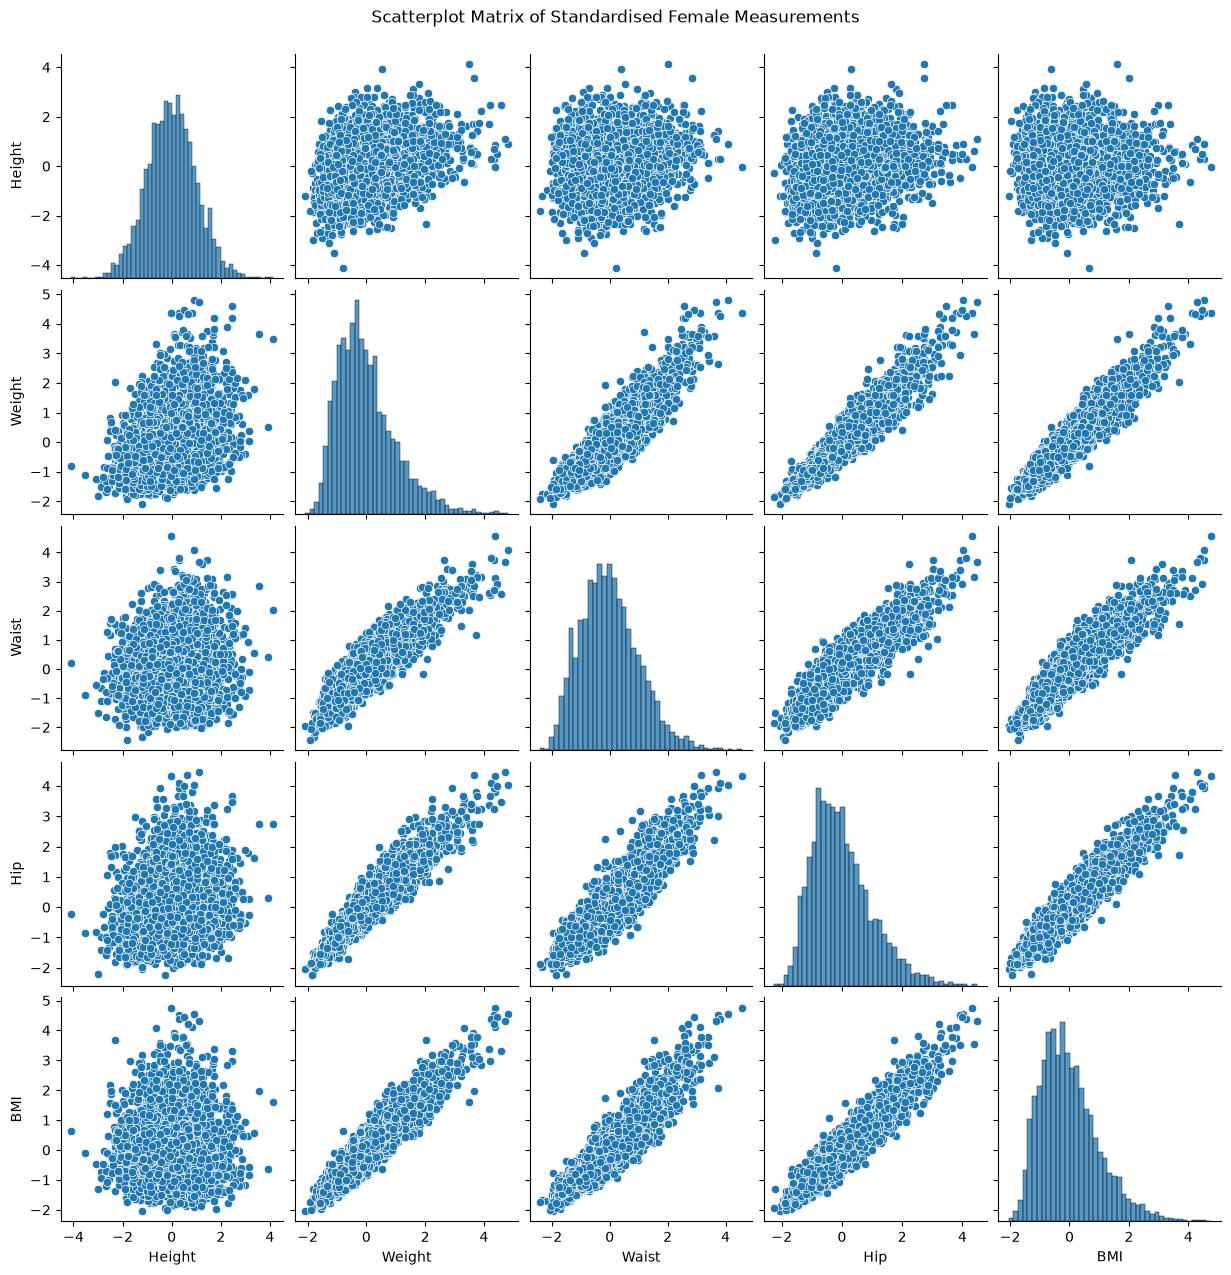

In [22]:
column_names = [
    "Height",
    "Weight",
    "Waist",
    "Hip",
    "BMI"
]

selected_df = pd.DataFrame(
    selected_data,
    columns=column_names
)

sns.pairplot(selected_df)
plt.suptitle(
    "Scatterplot Matrix of Standardised Female Measurements",
    y=1.02
)
plt.show()

In [23]:
# Pearson correlation
pearson_corr = selected_df.corr(method="pearson")

# Spearman correlation
spearman_corr = selected_df.corr(method="spearman")

print("PEARSON CORRELATION MATRIX")
print(pearson_corr.round(3))

print("\nSPEARMAN CORRELATION MATRIX")
print(spearman_corr.round(3))

PEARSON CORRELATION MATRIX
        Height  Weight  Waist    Hip    BMI
Height   1.000   0.345  0.127  0.203  0.033
Weight   0.345   1.000  0.905  0.947  0.946
Waist    0.127   0.905  1.000  0.897  0.921
Hip      0.203   0.947  0.897  1.000  0.944
BMI      0.033   0.946  0.921  0.944  1.000

SPEARMAN CORRELATION MATRIX
        Height  Weight  Waist    Hip    BMI
Height   1.000   0.339  0.109  0.205  0.020
Weight   0.339   1.000  0.900  0.947  0.938
Waist    0.109   0.900  1.000  0.888  0.923
Hip      0.205   0.947  0.888  1.000  0.934
BMI      0.020   0.938  0.923  0.934  1.000


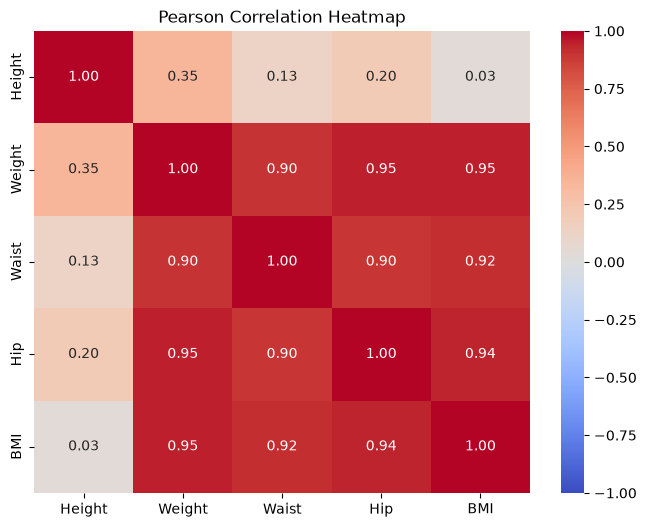

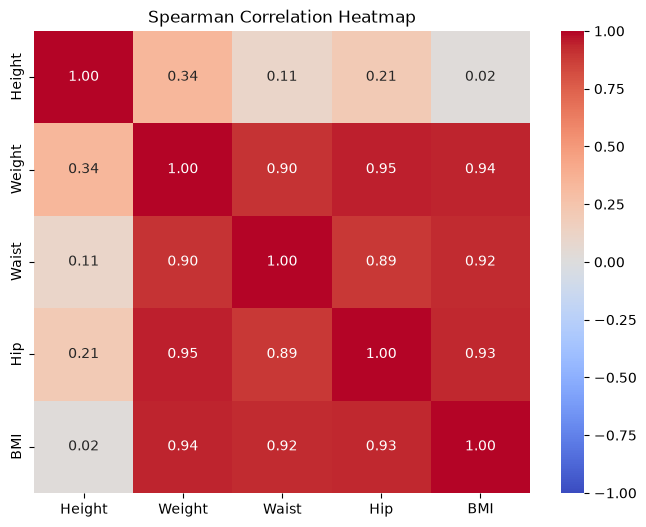

In [24]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Pearson Correlation Heatmap")
plt.show()


plt.figure(figsize=(8, 6))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Spearman Correlation Heatmap")
plt.show()

### Interpretation of Scatterplot Matrix and Correlation Analysis

The scatterplot matrix and correlation heatmaps reveal several relationships among the standardised female body measurements.

- Weight shows a very strong positive correlation with waist circumference (0.905), hip circumference (0.947), and BMI (0.946) according to Pearson correlation.
- Waist and hip circumferences are also strongly positively correlated (0.897).
- Height has relatively weak correlations with weight (0.345), waist (0.127), hip (0.203), and BMI (0.033).
- The correlation between height and BMI is almost zero, indicating a negligible linear relationship in this dataset.
- Spearman correlation coefficients show similar patterns to Pearson coefficients, suggesting that these relationships are also strongly monotonic.

Overall, weight, waist circumference, hip circumference, and BMI are strongly associated with one another, whereas height has comparatively weak relationships with the other measurements.

# 9. Waist-to-Height and Waist-to-Hip Ratios

In [25]:
# female waist-to-height ratio
female_whtr = female[:, 6] / female[:, 1]

# female waist-to-hip ratio
female_whr = female[:, 6] / female[:, 5]

# male waist-to-height ratio
male_whtr = male[:, 6] / male[:, 1]

# male waist-to-hip ratio
male_whr = male[:, 6] / male[:, 5]

In [26]:
female = np.column_stack((female, female_whtr, female_whr))
male = np.column_stack((male, male_whtr, male_whr))

print("Updated female matrix shape:", female.shape)
print("Updated male matrix shape:", male.shape)

print("\nFirst 5 female rows:")
print(female[:5])

print("\nFirst 5 male rows:")
print(male[:5])

Updated female matrix shape: (4221, 10)
Updated male matrix shape: (4081, 9)

First 5 female rows:
[[ 97.1        160.2         34.7         40.8         35.8
  126.1        117.9         37.83504078   0.73595506   0.93497224]
 [ 91.1        152.7         33.5         33.          38.5
  125.5        103.1         39.06972037   0.67518009   0.82151394]
 [ 73.         161.2         37.4         38.          31.8
  106.2         92.          28.09265496   0.5707196    0.86629002]
 [ 61.7        157.4         38.          34.7         29.
  101.          90.5         24.90437849   0.57496823   0.8960396 ]
 [ 55.4        154.6         34.6         34.          28.3
   92.5         73.2         23.17879132   0.47347995   0.79135135]]

First 5 male rows:
[[ 98.8        182.3         42.          40.1         38.2
  108.2        120.4          0.66044981   1.11275416]
 [ 74.3        184.2         41.1         41.          30.2
   94.5         86.8          0.47122693   0.91851852]
 [103.7    

# 10. Comparison of Body Measurement Ratios

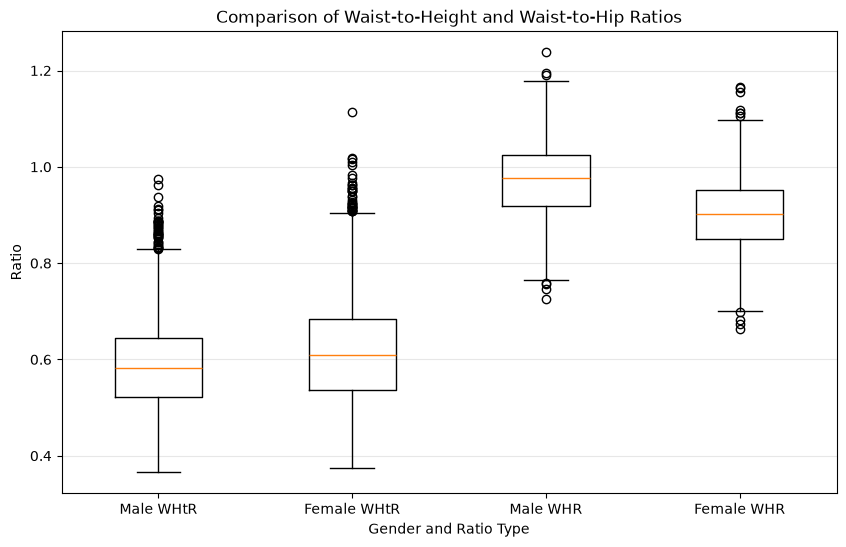

In [27]:
plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        male[:, 7],
        female[:, 8],
        male[:, 8],
        female[:, 9]
    ],
    tick_labels=[
        "Male WHtR",
        "Female WHtR",
        "Male WHR",
        "Female WHR"
    ]
)

plt.title("Comparison of Waist-to-Height and Waist-to-Hip Ratios")
plt.ylabel("Ratio")
plt.xlabel("Gender and Ratio Type")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretation of Waist-to-Height and Waist-to-Hip Ratios

The boxplot compares the waist-to-height ratio (WHtR) and waist-to-hip ratio (WHR) of male and female participants.

- The female group has a higher median waist-to-height ratio (approximately 0.61) compared to the male group (approximately 0.58).
- The male group has a higher median waist-to-hip ratio (approximately 0.98) compared to the female group (approximately 0.90).
- The female waist-to-height ratio shows slightly greater variation in the middle 50% of observations.
- Both male and female groups contain outliers, indicating participants with unusually high or low ratio values.

Overall, the results show differences in the distribution of these body measurement ratios between male and female participants.

# 11. Advantages and Disadvantages of BMI, WHtR and WHR

### Advantages and Disadvantages of BMI, WHtR and WHR

**BMI (Body Mass Index)**

Advantages:
- Simple and inexpensive to calculate.
- Requires only weight and height measurements.
- Useful for assessing weight status in large populations.

Disadvantages:
- Does not distinguish between muscle mass and fat mass.
- Does not indicate the distribution of body fat.
- May provide misleading results for individuals with high muscle mass.

**WHtR (Waist-to-Height Ratio)**

Advantages:
- Considers waist circumference relative to height.
- Provides an indication of abdominal fat distribution.
- Easy to calculate and interpret.

Disadvantages:
- Requires accurate waist and height measurements.
- Can be affected by measurement techniques.
- Does not directly measure body fat.

**WHR (Waist-to-Hip Ratio)**

Advantages:
- Provides information about fat distribution around the waist and hips.
- Simple to calculate.
- Useful in population-level health studies.

Disadvantages:
- Requires accurate waist and hip measurements.
- Can be affected by variations in body shape.
- Does not directly measure total body fat.

**Conclusion:** BMI, WHtR and WHR provide different perspectives on body measurements. Using them together can provide more information than relying on a single measurement, although none of them independently provides a complete assessment of body composition or health.

# 12. Identifying Participants with Lowest and Highest BMI

In [31]:
# Extract BMI values from the female dataset
bmi_values = female[:, 7]

# Get indices sorted by BMI
sorted_indices = np.argsort(bmi_values)

# Five lowest BMI participants
lowest_bmi_indices = sorted_indices[:5]

# Five highest BMI participants
highest_bmi_indices = sorted_indices[-5:][::-1]

print("Five lowest BMI values:")
print(bmi_values[lowest_bmi_indices])

print("\nFive highest BMI values:")
print(bmi_values[highest_bmi_indices])

Five lowest BMI values:
[14.20340054 14.63273036 14.81882399 15.04456103 15.42130871]

Five highest BMI values:
[67.03689493 65.33289802 65.11544005 64.7070699  64.19895366]


In [32]:
print("STANDARDISED MEASUREMENTS OF FIVE LOWEST BMI PARTICIPANTS")
print(zfemale[lowest_bmi_indices])

print("\nSTANDARDISED MEASUREMENTS OF FIVE HIGHEST BMI PARTICIPANTS")
print(zfemale[highest_bmi_indices])

STANDARDISED MEASUREMENTS OF FIVE LOWEST BMI PARTICIPANTS
[[-2.07978523 -1.22299143 -1.5478402  -1.16905675 -2.1947611  -2.0405496
  -1.94212128 -2.05024028]
 [-1.88017988 -0.18929313 -1.71835247  0.38637892 -2.4443617  -1.85491922
  -2.05708015 -1.99487987]
 [-1.53667299  1.80730222  0.62619127  0.5730312  -2.26607556 -1.6756899
  -1.7064556  -1.97088383]
 [-1.843044   -0.26009438 -0.22637009  0.51081377 -2.30173278 -2.25178417
  -1.85590213 -1.94177591]
 [-1.61094475  0.88688592 -0.09848588  0.47970506 -2.21258971 -1.82931504
  -1.71220354 -1.89319577]]

STANDARDISED MEASUREMENTS OF FIVE HIGHEST BMI PARTICIPANTS
[[ 4.36328993 -0.03353037 -0.05585782 -0.17357792  2.77942222  4.31569054
   4.57029862  4.76243308]
 [ 4.8042785   0.88688592  2.11817365  1.81737973  3.77782461  4.02124236
   4.08172343  4.54270932]
 [ 4.34936397  0.27799514  2.84285081  1.94181459  4.36616887  3.9188256
   3.75409065  4.51466896]
 [ 4.45612963  0.50455915  1.69189297 -1.13794804  3.34993787  3.98283607
  

### Interpretation of Participants with Lowest and Highest BMI

The NumPy `argsort()` function was used to identify the five participants with the lowest and highest BMI values.

The five lowest BMI values range from approximately 14.20 to 15.42, whereas the five highest BMI values range from approximately 64.20 to 67.04.

The corresponding standardised measurements were extracted from the `zfemale` matrix.

The standardised BMI values of participants with the lowest BMI are negative, indicating that their BMI values are below the dataset mean. In contrast, the standardised BMI values of participants with the highest BMI are positive, indicating that their BMI values are above the dataset mean.

This analysis demonstrates how NumPy sorting and indexing can be used to identify individuals with extreme values and examine their corresponding measurements.

# Conclusion

This project explored multidimensional body measurement data using NumPy and Python data visualization libraries.

The analysis included loading and manipulating numerical datasets, comparing weight distributions, calculating statistical aggregates, computing BMI, and standardising measurements using Z-scores.

Scatterplot matrices and correlation coefficients were used to investigate relationships between different body measurements. Waist-to-height and waist-to-hip ratios were also calculated and compared between male and female participants.

Finally, NumPy sorting and indexing techniques were applied to identify participants with the lowest and highest BMI values.

Overall, this project provided practical experience in numerical computing, statistical analysis, data manipulation, and visualization using Python libraries such as NumPy, Pandas, Matplotlib, Seaborn, and SciPy.